In [1]:
!pip install ucimlrepo

## 1. Setup & Data Verification

In [2]:
import pandas as pd
from ucimlrepo import fetch_ucirepo

# Fetch the Heart Failure Clinical Records dataset (ID = 519)
heart_failure = fetch_ucirepo(id=519)

# Extract the features (X) and target (y)
X = heart_failure.data.features
y = heart_failure.data.targets

# Combine them into a single clean DataFrame called 'df'
df = pd.concat([X, y], axis=1)

# Verify it loaded properly (should show 299 rows and 13 columns)
print(df.shape)
df.head()


(299, 13)


,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,death_event
0,75.0,0,582,0,20,1,265000.00,1.9,130,1,0,4,1
1,55.0,0,7861,0,38,0,263358.03,1.1,136,1,0,6,1
2,65.0,0,146,0,20,0,162000.00,1.3,129,1,1,7,1
3,50.0,1,111,0,20,0,210000.00,1.9,137,1,0,7,1
4,65.0,1,160,1,20,0,327000.00,2.7,116,0,0,8,1


In [3]:
from google.colab import sheets
sheet = sheets.InteractiveSheet(df=df)

https://docs.google.com/spreadsheets/d/1T2Cr9PSxHcEvGXxPbvY2h1ABfKzvceNc_cuqAcnBCt8/edit#gid=0


In [4]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns


In [5]:
# 1. Preview the first 5 rows of the table
display(df.head())

# 2. Check column names, row count (299), and data types (int64 / float64)
df.info()

# 3. Count any blank or missing cells in every column (should all be 0)
print(df.isnull().sum())


,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,death_event
0,75.0,0,582,0,20,1,265000.00,1.9,130,1,0,4,1
1,55.0,0,7861,0,38,0,263358.03,1.1,136,1,0,6,1
2,65.0,0,146,0,20,0,162000.00,1.3,129,1,1,7,1
3,50.0,1,111,0,20,0,210000.00,1.9,137,1,0,7,1
4,65.0,1,160,1,20,0,327000.00,2.7,116,0,0,8,1


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 299 entries, 0 to 298
Data columns (total 13 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   age                       299 non-null    float64
 1   anaemia                   299 non-null    int64  
 2   creatinine_phosphokinase  299 non-null    int64  
 3   diabetes                  299 non-null    int64  
 4   ejection_fraction         299 non-null    int64  
 5   high_blood_pressure       299 non-null    int64  
 6   platelets                 299 non-null    float64
 7   serum_creatinine          299 non-null    float64
 8   serum_sodium              299 non-null    int64  
 9   sex                       299 non-null    int64  
 10  smoking                   299 non-null    int64  
 11  time                      299 non-null    int64  
 12  death_event               299 non-null    int64  
dtypes: float64(3), int64(10)
memory usage: 30.5 KB
age               

In [6]:
print(df.columns.tolist())


['age', 'anaemia', 'creatinine_phosphokinase', 'diabetes', 'ejection_fraction', 'high_blood_pressure', 'platelets', 'serum_creatinine', 'serum_sodium', 'sex', 'smoking', 'time', 'death_event']


## 2. Exploratory Data Analysis & Visualizations

In [7]:
# Table 1: Calculate the average (mean) for every column, split by survival
print("GROUP MEANS:")
display(df.groupby('death_event').mean().round(2))

# Table 2: Calculate the middle value (median) for every column, split by survival
print("GROUP MEDIANS:")
display(df.groupby('death_event').median().round(2))


GROUP MEANS:


,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time
death_event,,,,,,,,,,,,
0,58.76,0.41,540.05,0.42,40.27,0.33,266657.49,1.18,137.22,0.65,0.33,158.34
1,65.22,0.48,670.20,0.42,33.47,0.41,256381.04,1.84,135.38,0.65,0.31,70.89


GROUP MEDIANS:


,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time
death_event,,,,,,,,,,,,
0,60.0,0.0,245.0,0.0,38.0,0.0,263000.0,1.0,137.0,1.0,0.0,172.0
1,65.0,0.0,259.0,0.0,30.0,0.0,258500.0,1.3,135.5,1.0,0.0,44.5


/tmp/ipykernel_17186/2915394751.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='death_event', y='serum_creatinine', data=df, palette='Set2')


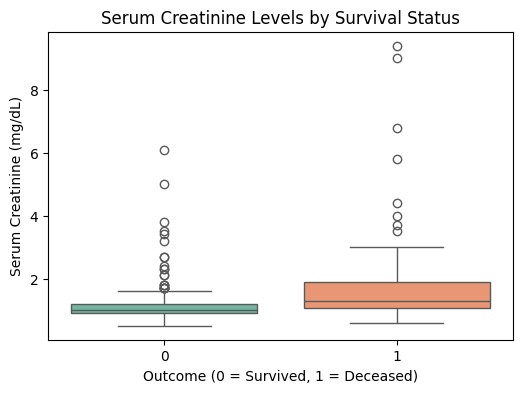

In [8]:
plt.figure(figsize=(6, 4))
sns.boxplot(x='death_event', y='serum_creatinine', data=df, palette='Set2')
plt.title('Serum Creatinine Levels by Survival Status')
plt.xlabel('Outcome (0 = Survived, 1 = Deceased)')
plt.ylabel('Serum Creatinine (mg/dL)')
plt.savefig('creatinine_boxplot.png', dpi=300, bbox_inches='tight')
plt.show()


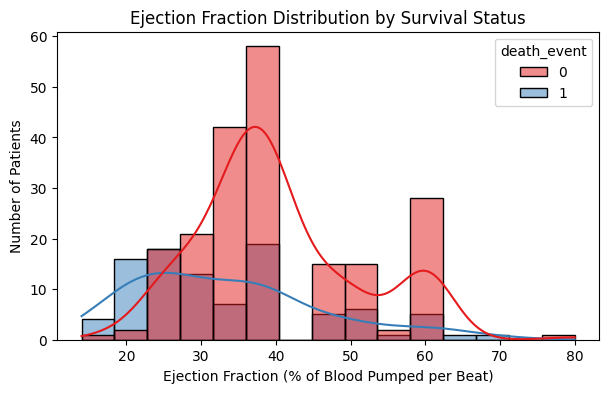

In [9]:
plt.figure(figsize=(7, 4))
sns.histplot(data=df, x='ejection_fraction', hue='death_event', kde=True, bins=15, palette='Set1')
plt.title('Ejection Fraction Distribution by Survival Status')
plt.xlabel('Ejection Fraction (% of Blood Pumped per Beat)')
plt.ylabel('Number of Patients')
plt.savefig('ejection_fraction_dist.png', dpi=300, bbox_inches='tight')
plt.show()


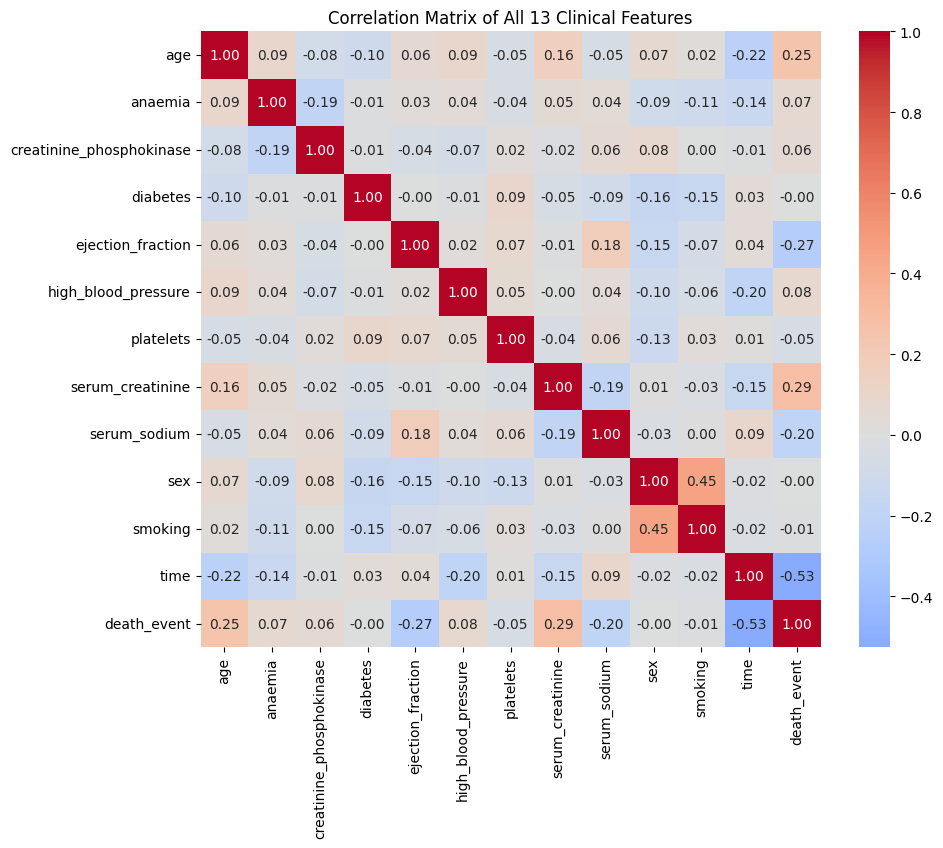

In [10]:
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation Matrix of All 13 Clinical Features')
plt.savefig('correlation_heatmap.png', dpi=300, bbox_inches='tight')
plt.show()


## 3. Statistical Hypothesis Testing (Mann-Whitney U)

In [11]:
from scipy.stats import mannwhitneyu

# 1. Split the main table into two separate tables: survivors vs. non-survivors
survived = df[df['death_event'] == 0]
deceased = df[df['death_event'] == 1]

# 2. List the top clinical features we want to test
biomarkers = ['age', 'ejection_fraction', 'serum_creatinine', 'serum_sodium']

# 3. Loop through each biomarker and run the Mann-Whitney U test
for marker in biomarkers:
  stat, p_value = mannwhitneyu(survived[marker], deceased[marker])
  print(f'{marker}: p-value = {p_value:.6f}')


age: p-value = 0.000167
ejection_fraction: p-value = 0.000001
serum_creatinine: p-value = 0.000000
serum_sodium: p-value = 0.000293


## 4. Machine Learning Models & Validation

In [12]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. Separate inputs (X) from the answer key (y), dropping 'time' to prevent data leakage
X = df.drop(['death_event', 'time'], axis=1)
y = df['death_event']

# 2. Split into 80% practice data (train) and 20% final exam data (test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# 3. Put all numbers on the same scale so big numbers don't overpower small ones
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


In [13]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, roc_auc_score

# 1. Train Model 1: Logistic Regression (simple linear baseline)
log_model = LogisticRegression(random_state=42)
log_model.fit(X_train_scaled, y_train)
log_preds = log_model.predict(X_test_scaled)
log_probs = log_model.predict_proba(X_test_scaled)[:, 1]

print('--- LOGISTIC REGRESSION ---')
print(classification_report(y_test, log_preds))
print(f'ROC-AUC Score: {roc_auc_score(y_test, log_probs):.3f}\n')

# 2. Train Model 2: Random Forest (combines 100 decision trees)
rf_model = RandomForestClassifier(random_state=42)
rf_model.fit(X_train_scaled, y_train)
rf_preds = rf_model.predict(X_test_scaled)
rf_probs = rf_model.predict_proba(X_test_scaled)[:, 1]

print('--- RANDOM FOREST ---')
print(classification_report(y_test, rf_preds))
print(f'ROC-AUC Score: {roc_auc_score(y_test, rf_probs):.3f}')


--- LOGISTIC REGRESSION ---
              precision    recall  f1-score   support

           0       0.74      0.85      0.80        41
           1       0.54      0.37      0.44        19

    accuracy                           0.70        60
   macro avg       0.64      0.61      0.62        60
weighted avg       0.68      0.70      0.68        60

ROC-AUC Score: 0.745

--- RANDOM FOREST ---
              precision    recall  f1-score   support

           0       0.74      0.85      0.80        41
           1       0.54      0.37      0.44        19

    accuracy                           0.70        60
   macro avg       0.64      0.61      0.62        60
weighted avg       0.68      0.70      0.68        60

ROC-AUC Score: 0.795


## 5. Biomarker Feature Importance

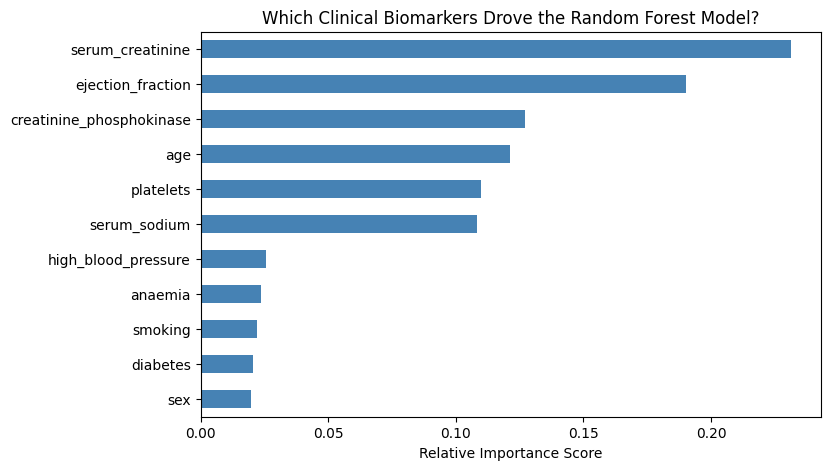

In [14]:
importances = pd.Series(rf_model.feature_importances_, index=X.columns).sort_values()

plt.figure(figsize=(8, 5))
importances.plot(kind='barh', color='steelblue')
plt.title('Which Clinical Biomarkers Drove the Random Forest Model?')
plt.xlabel('Relative Importance Score')
plt.savefig('feature_importance.png', dpi=300, bbox_inches='tight')
plt.show()
